In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv("Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (10000, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

Statistical Summary:


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["Exited"].value_counts())

Missing Values:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Duplicate Records: 0

Target Distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64


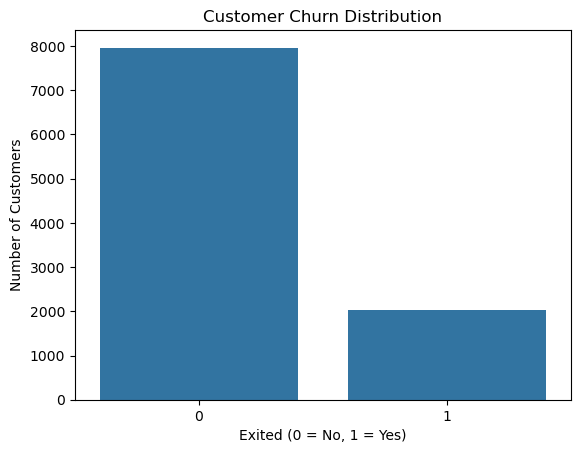

In [5]:
sns.countplot(x="Exited", data=df)
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

In [6]:
df = df.drop(["RowNumber", "CustomerId", "Surname"], axis=1)

df = df.drop_duplicates()

df = pd.get_dummies(df, columns=["Geography", "Gender"], drop_first=True)

X = df.drop("Exited", axis=1)
y = df["Exited"]

print(X.head())

   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42       2       0.00              1          1   
1          608   41       1   83807.86              1          0   
2          502   42       8  159660.80              3          1   
3          699   39       1       0.00              2          0   
4          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Geography_Germany  Geography_Spain  \
0               1        101348.88              False            False   
1               1        112542.58              False             True   
2               0        113931.57              False            False   
3               0         93826.63              False            False   
4               1         79084.10              False             True   

   Gender_Male  
0        False  
1        False  
2        False  
3        False  
4        False  


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 11)
Testing Data: (2000, 11)


In [8]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [9]:
model = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=200,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10
)

model.fit(X_train, y_train)

MLPClassifier(early_stopping=True, hidden_layer_sizes=(16, 8), random_state=42)

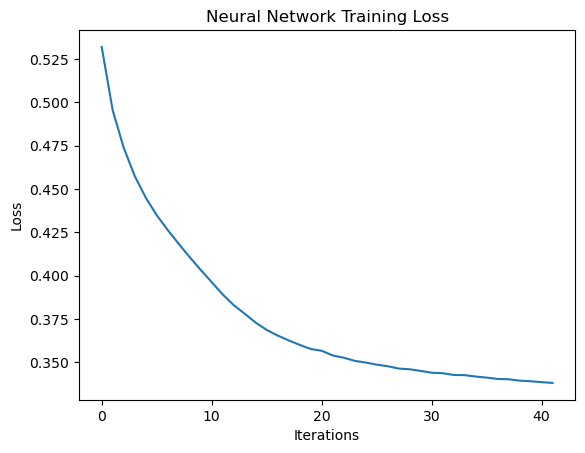

In [10]:
plt.plot(model.loss_curve_)
plt.title("Neural Network Training Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.show()

In [11]:
y_pred = model.predict(X_test)

print("Predicted Values:")
print(y_pred[:20])

print("\nActual Values:")
print(y_test.iloc[:20].values)

Predicted Values:
[0 0 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0]

Actual Values:
[0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0]


In [12]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 85.75 %

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.96      0.91      1593
           1       0.74      0.47      0.57       407

    accuracy                           0.86      2000
   macro avg       0.81      0.71      0.74      2000
weighted avg       0.85      0.86      0.84      2000



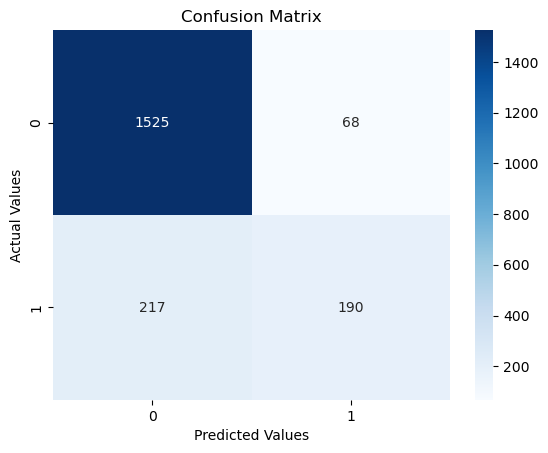

In [13]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix")
plt.show()

In [14]:
print("Bank Customer Churn Prediction")
print("------------------------------")
print("Model: Multi-Layer Perceptron")
print("Accuracy:", accuracy * 100, "%")
print("\nConfusion Matrix:")
print(cm)

Bank Customer Churn Prediction
------------------------------
Model: Multi-Layer Perceptron
Accuracy: 85.75 %

Confusion Matrix:
[[1525   68]
 [ 217  190]]


In [15]:

# THEORY: BANK CUSTOMER CHURN PREDICTION USING NEURAL NETWORK
#
# 1. INTRODUCTION
#
# Customer churn refers to a situation in which a customer stops
# using the services of a company or organization.
#
# In the banking sector, customer churn occurs when a customer
# closes their account or stops using banking services.
#
# Predicting customer churn helps banks identify customers
# who are likely to leave and take preventive actions to
# improve customer retention.
#
# Machine Learning algorithms can analyze customer information
# and identify patterns associated with customer churn.
#
# In this practical, a Neural Network classifier is developed
# to predict whether a bank customer will leave the bank.
#
#
# 2. DATASET DESCRIPTION
#
# The Churn_Modelling.csv dataset contains customer information
# used to predict whether a customer will leave the bank.
#
# Important attributes include:
#
# 1. CreditScore: Credit score of the customer.
# 2. Geography: Country or geographical location.
# 3. Gender: Gender of the customer.
# 4. Age: Age of the customer.
# 5. Tenure: Number of years the customer has been with the bank.
# 6. Balance: Account balance of the customer.
# 7. NumOfProducts: Number of banking products used.
# 8. HasCrCard: Indicates whether the customer has a credit card.
# 9. IsActiveMember: Indicates whether the customer is active.
# 10. EstimatedSalary: Estimated salary of the customer.
# 11. Exited: Target variable indicating customer churn.
#
# The Exited column is the target variable:
# 0 - Customer stayed with the bank.
# 1 - Customer left the bank.
#
# Columns such as RowNumber, CustomerId and Surname are removed
# because they are identifiers or do not provide useful
# predictive information for this model.
#
#
# 3. DATA PREPROCESSING
#
# Data preprocessing is performed to clean and prepare the
# dataset before training the Neural Network.
#
# First, the dataset is loaded using Pandas.
# Missing values and duplicate records are checked.
#
# Unnecessary columns such as RowNumber, CustomerId and
# Surname are removed.
#
# The Geography and Gender columns contain categorical data.
# Machine Learning models require numerical input, so these
# columns are converted into numerical form using One-Hot Encoding.
#
# One-Hot Encoding creates separate binary columns for
# different categories.
#
# The independent features are stored in X, while the target
# variable Exited is stored in y.
#
#
# 4. TRAIN-TEST SPLITTING
#
# The dataset is divided into training and testing sets
# using the train_test_split() function.
#
# 80% of the records are used for training the Neural Network,
# while the remaining 20% are used for testing.
#
# The stratify parameter maintains the proportion of churn
# and non-churn customers in both sets.
#
# This helps evaluate the model using unseen customer records.
#
#
# 5. FEATURE SCALING
#
# Feature scaling is the process of bringing numerical features
# to a similar scale.
#
# StandardScaler is used to standardize the input features.
#
# The formula is:
#
# Z = (X - Mean) / Standard Deviation
#
# Where:
# X = Original feature value
# Mean = Mean of the feature
# Standard Deviation = Standard deviation of the feature
#
# Standardization generally produces features with a mean of 0
# and a standard deviation of 1.
#
# Scaling is important for Neural Networks because features
# with very different numerical ranges can affect training.
#
# The scaler is fitted on the training data and then used
# to transform both training and testing data.
#
#
# 6. ARTIFICIAL NEURAL NETWORK
#
# An Artificial Neural Network (ANN) is a Machine Learning
# model inspired by the structure and functioning of the
# human brain.
#
# It consists of interconnected processing units called neurons.
#
# The main layers of a Neural Network are:
#
# 1. Input Layer:
#    Receives the input features from the dataset.
#
# 2. Hidden Layer:
#    Processes information using weights, biases and activation
#    functions to learn patterns from the data.
#
# 3. Output Layer:
#    Produces the final prediction.
#
# A neuron calculates a weighted sum of its inputs and applies
# an activation function.
#
# The basic mathematical representation is:
#
# Z = W1X1 + W2X2 + ... + WnXn + b
#
# Output = Activation Function(Z)
#
# Where:
# X = Input features
# W = Weights
# b = Bias
#
#
# 7. MULTI-LAYER PERCEPTRON (MLP)
#
# A Multi-Layer Perceptron is a type of feed-forward
# Artificial Neural Network.
#
# It contains an input layer, one or more hidden layers
# and an output layer.
#
# In this practical, MLPClassifier from the Scikit-learn
# library is used to implement the Neural Network.
#
# The model uses two hidden layers containing 16 and 8 neurons.
#
# The ReLU activation function is used in the hidden layers.
#
# ReLU stands for Rectified Linear Unit.
#
# ReLU(x) = max(0, x)
#
# It converts negative values to zero and keeps positive
# values unchanged.
#
# The Adam optimizer is used to update the network weights
# during training.
#
# The model learns by comparing predicted outputs with
# actual outputs and adjusting its weights to reduce error.
#
#
# 8. MODEL TRAINING AND OPTIMIZATION
#
# During training, the Neural Network performs forward propagation
# to generate predictions.
#
# The prediction error is calculated using a loss function.
# The optimizer updates the weights to reduce this loss.
#
# This process is repeated for multiple iterations until
# the model learns suitable patterns.
#
# Early stopping is used to prevent unnecessary training
# and reduce overfitting.
#
# It stops training when the validation performance does
# not improve for a specified number of iterations.
#
# The loss curve represents the change in training loss
# during model training.
#
# A decreasing loss generally indicates that the model
# is learning from the training data.
#
#
# 9. MODEL PREDICTION
#
# After training, the Neural Network is used to predict
# whether customers in the testing dataset will leave the bank.
#
# The predicted values are compared with the actual Exited
# values to measure the model's performance.
#
#
# 10. MODEL EVALUATION
#
# The performance of the Neural Network is evaluated using
# accuracy, classification report and confusion matrix.
#
# A. ACCURACY
#
# Accuracy measures the percentage of correctly classified
# customer records.
#
# Accuracy = (TP + TN) / (TP + TN + FP + FN)
#
# B. CONFUSION MATRIX
#
# A confusion matrix evaluates the classification results
# by comparing actual and predicted classes.
#
# It contains four values:
#
# TP (True Positive): Customers who left and were correctly
# predicted as churned.
#
# TN (True Negative): Customers who stayed and were correctly
# predicted as retained.
#
# FP (False Positive): Customers who stayed but were predicted
# as churned.
#
# FN (False Negative): Customers who left but were predicted
# as retained.
#
# The confusion matrix helps understand the types of
# classification errors made by the model.
#
#
# 11. CONCLUSION
#
# In this practical, bank customer churn prediction is
# performed using an Artificial Neural Network.
#
# The dataset is loaded, cleaned and preprocessed.
# Categorical variables are converted into numerical form
# using One-Hot Encoding.
#
# The dataset is divided into training and testing sets,
# and numerical features are standardized using StandardScaler.
#
# An MLP Neural Network is trained using hidden layers,
# ReLU activation and the Adam optimizer.
#
# Early stopping is used to improve the training process.
#
# Finally, the model is evaluated using accuracy,
# classification report and confusion matrix.
#
# This approach helps banks identify customers who may
# leave their services and take suitable retention measures.
